# HLCA aging basins — H05 figures and mouse–human comparison

This executed notebook renders the committed H05 figure files. It does not refit a model or rerun the H04 tests.

In [1]:
from pathlib import Path
import anndata as ad
import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd()
HLCA_DATA = ROOT / 'benchmarks' / 'aging_hlca' / 'data'
FIGURE_DIR = ROOT / 'benchmarks' / 'figures' / 'aging_hlca'
primary = pd.read_csv(ROOT / 'benchmarks' / 'aging_hlca' / 'tests_primary.csv')
sensitivity = pd.read_csv(ROOT / 'benchmarks' / 'aging_hlca' / 'tests_sensitivity.csv')
mouse_human = pd.read_csv(ROOT / 'benchmarks' / 'aging_hlca' / 'mouse_human.csv')
manifest = pd.read_csv(FIGURE_DIR / 'MANIFEST.csv')
print({'primary_types': len(primary), 'sensitivity_rows': len(sensitivity), 'matched_pairs': len(mouse_human), 'figure_files': len(manifest)})

{'primary_types': 13, 'sensitivity_rows': 59, 'matched_pairs': 2, 'figure_files': 20}


## Frozen primary outcome

The H04 outcome is retained verbatim. H05 is a rendering and descriptive-comparison task; sensitivity analyses do not alter the primary header.

In [2]:
print('isotropic noise increase; no aging claim beyond stiffness — no majority stiffness change')
display(primary[['ann_level_3', 'iso_pass', 'ant_pass', 'stiff_class']])

isotropic noise increase; no aging claim beyond stiffness — no majority stiffness change


,ann_level_3,iso_pass,ant_pass,stiff_class
0,AT2,False,False,none
1,Basal,False,False,none
2,Dendritic cells,False,False,none
3,EC arterial,False,False,none
4,EC capillary,False,True,none
5,EC venous,False,False,none
6,Fibroblasts,False,False,none
7,Innate lymphoid cell NK,False,False,none
8,Macrophages,False,False,none
9,Monocytes,False,False,none


## Primary test overview

Shows the 13 frozen-eligible types. Isotropy and anticipation compare their stored statistic with the H04 stored 95% permutation threshold; stiffness shows the stored slope and its call. The stiffness null q95 was not persisted by H04, so no band is fabricated.

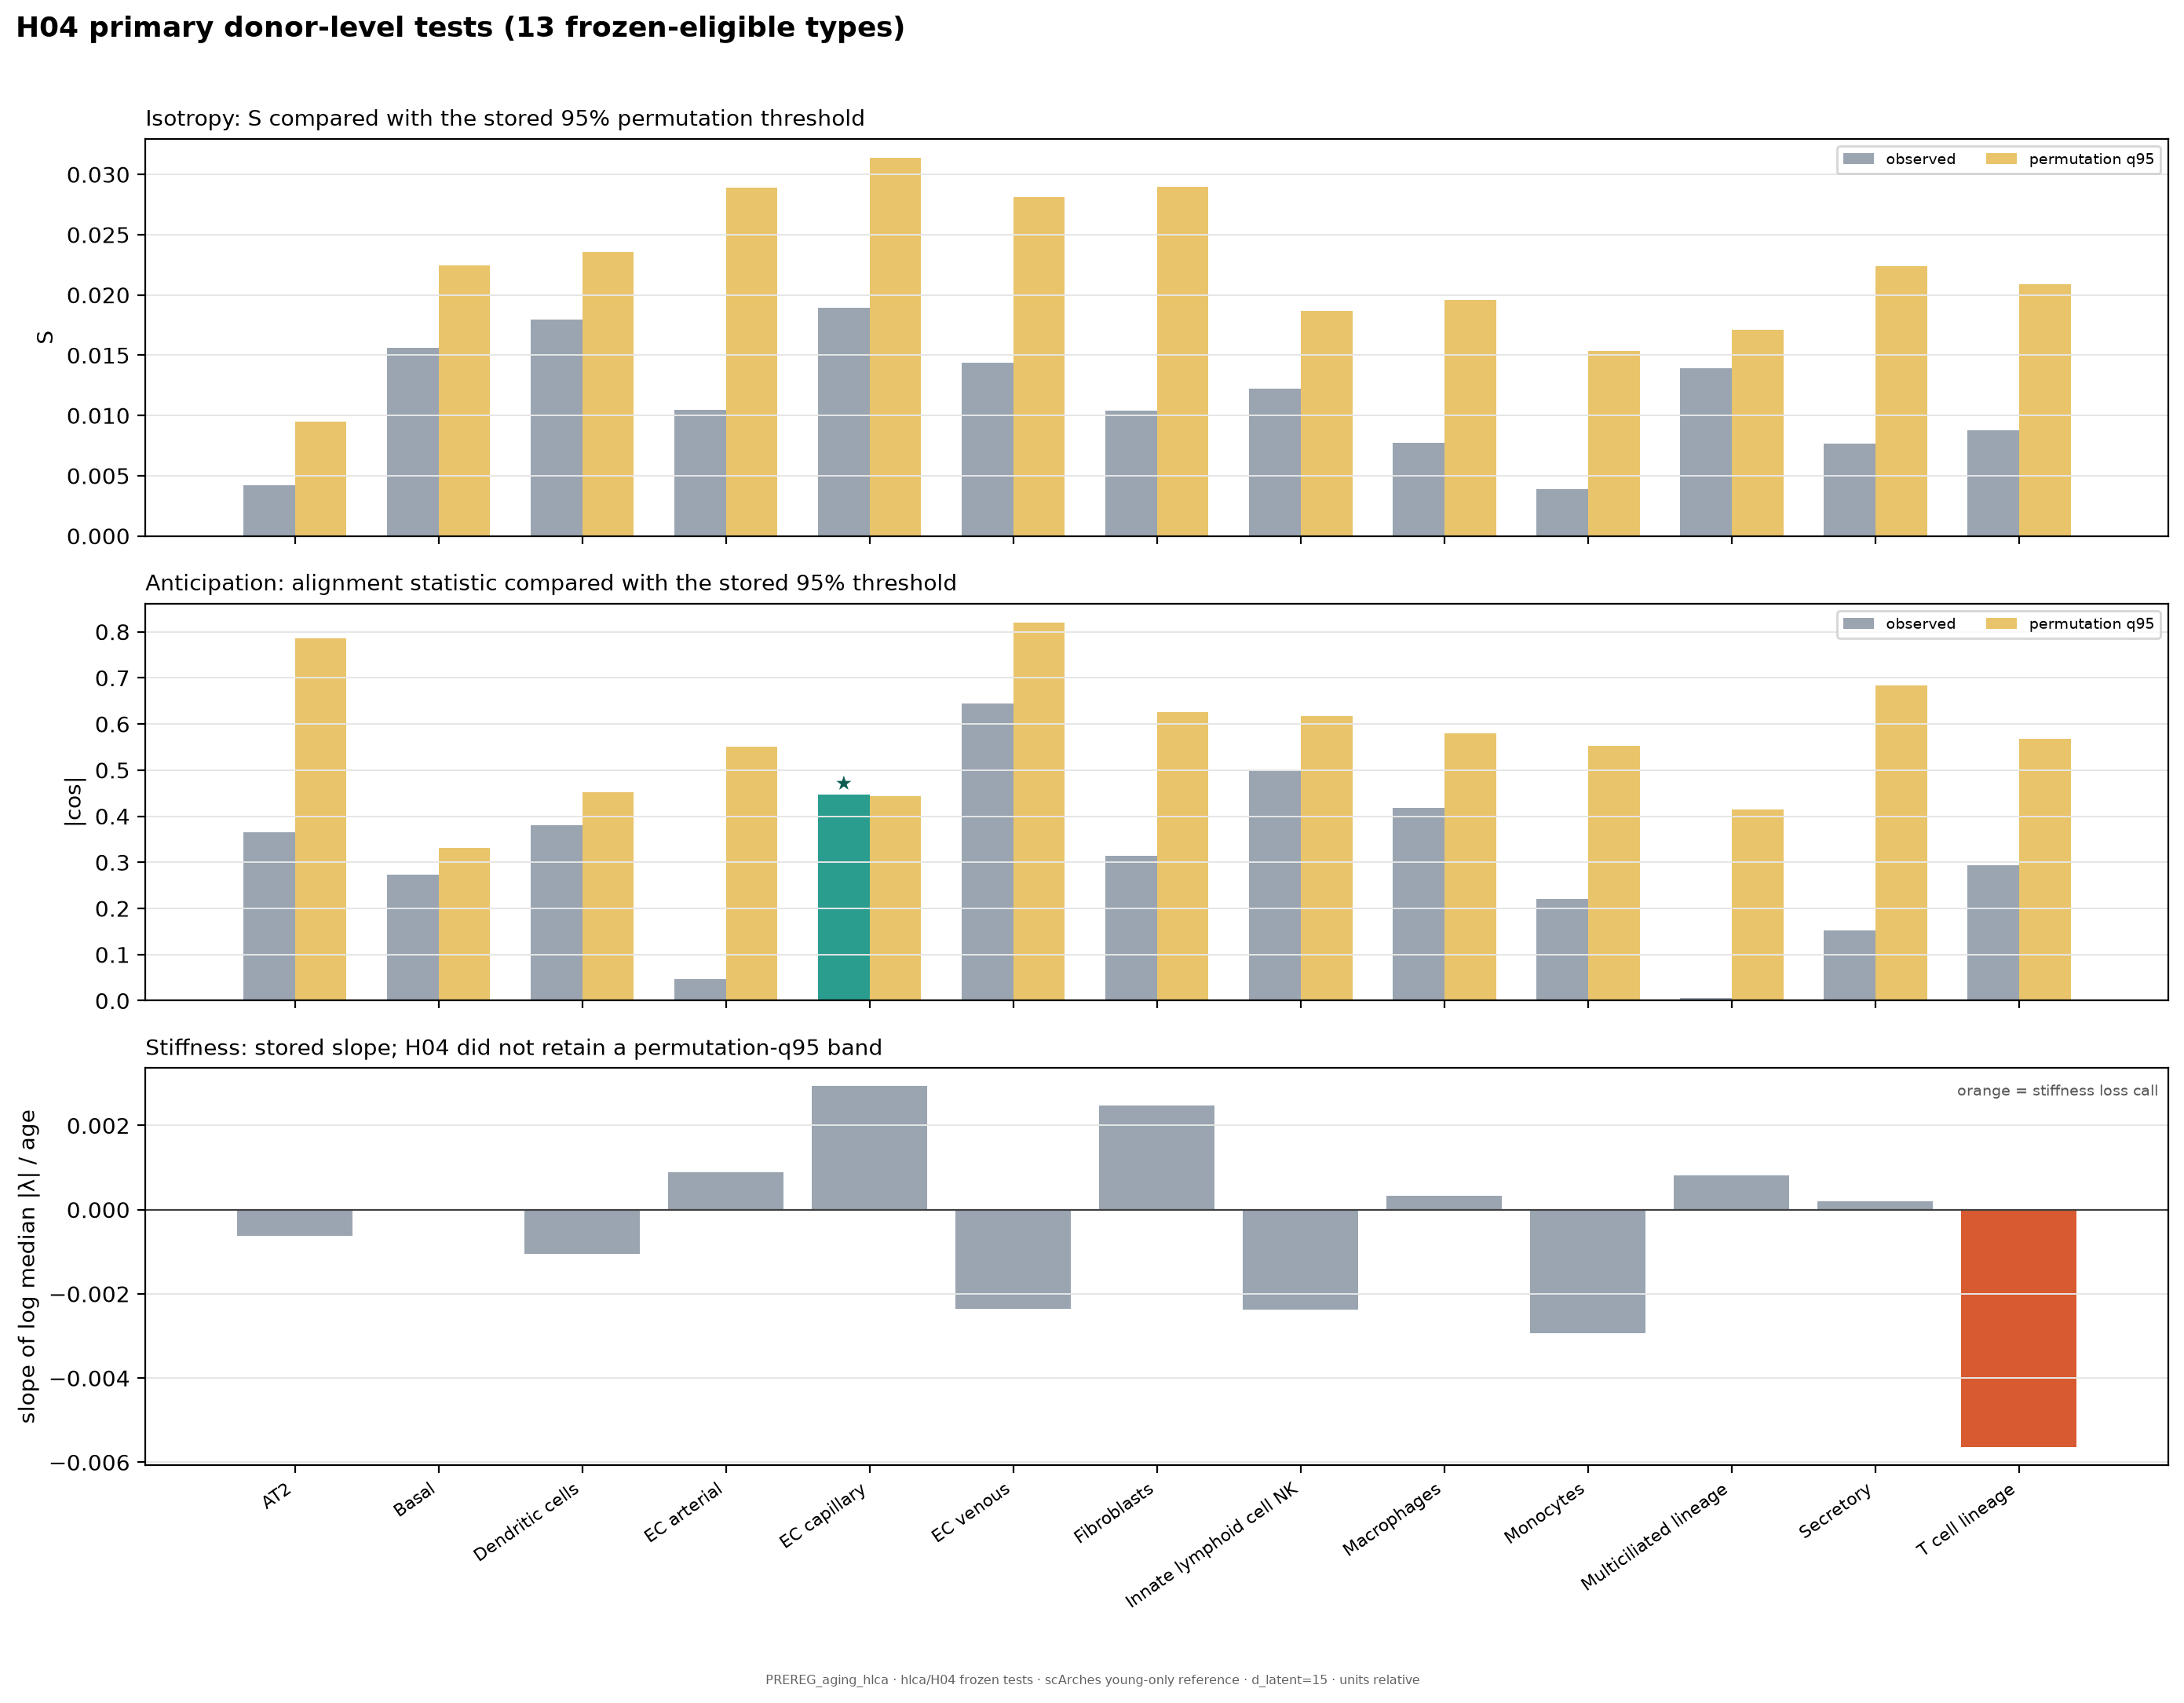

In [3]:
display(Image(filename=str(FIGURE_DIR / 'tests_overview.png'), width=1000))

## Sensitivity calls

Shows the stored primary and §7(a–f) calls as isotropy / anticipation / stiffness. Grey cells are types that became ineligible in the restricted subset.

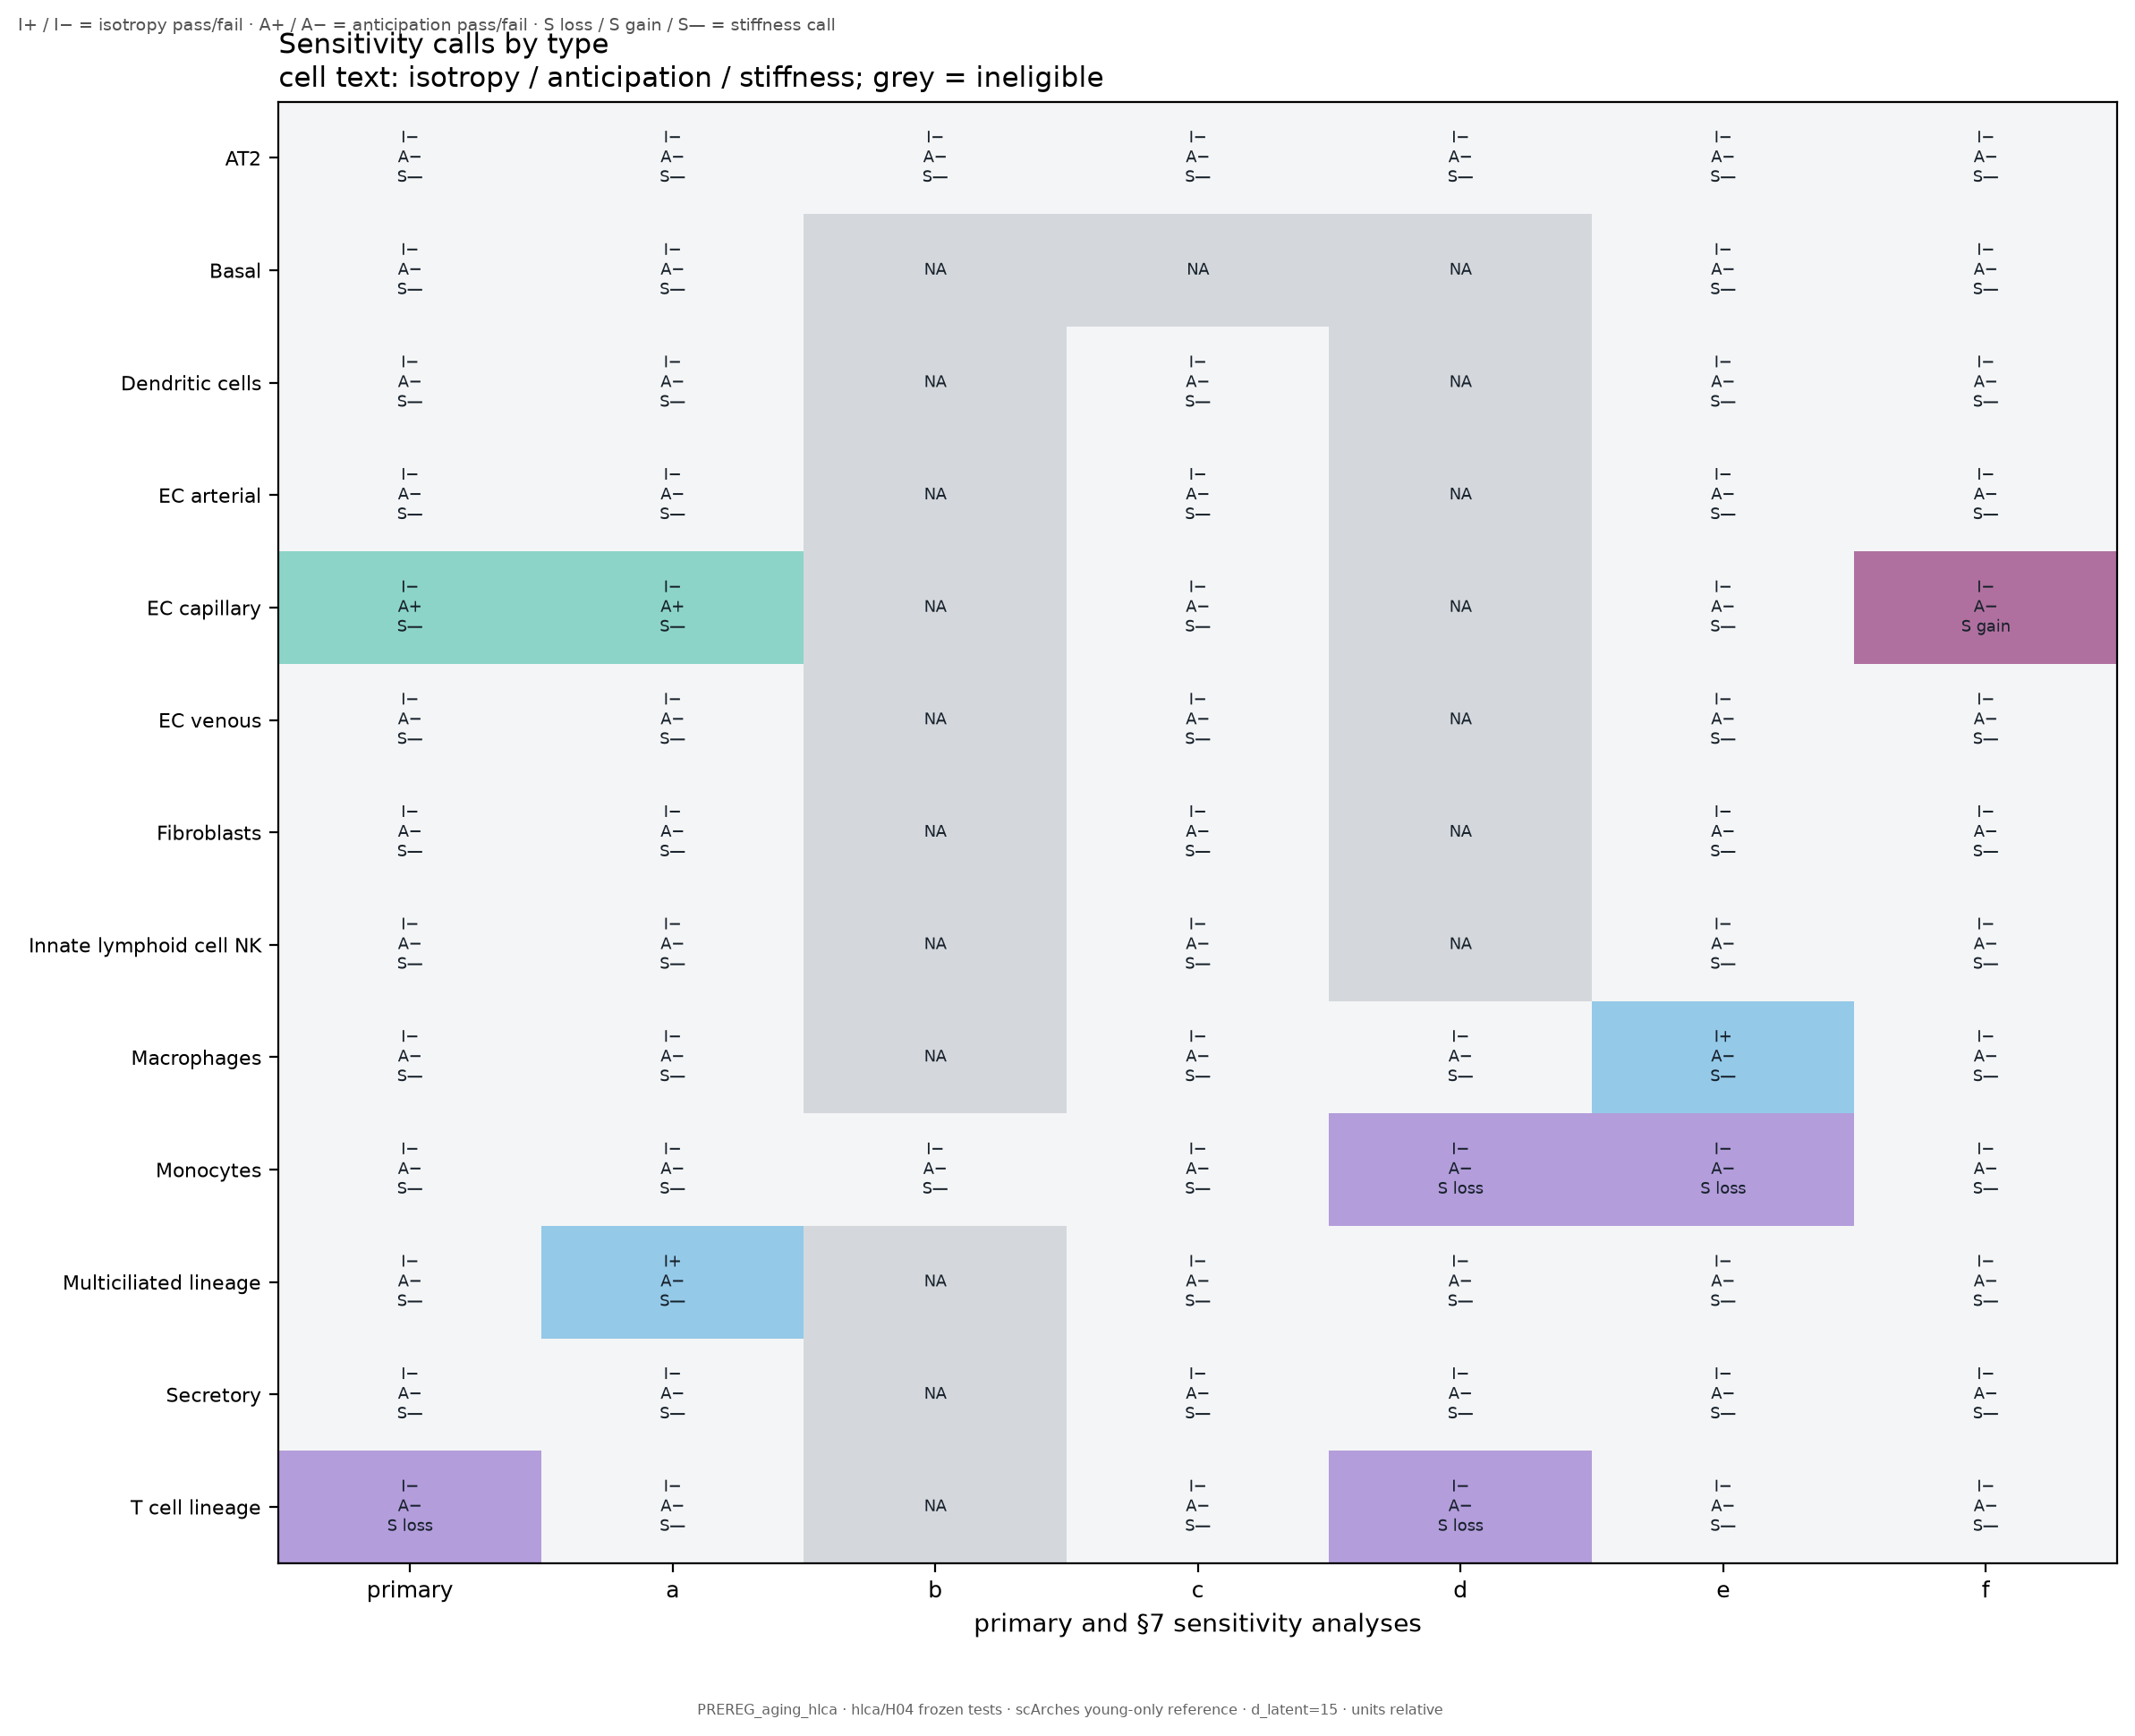

In [4]:
display(Image(filename=str(FIGURE_DIR / 'sensitivity_heatmap.png'), width=1000))

## Donor stiffness against age

Shows stored primary donor-level `log median |λ|` values against age, coloured by `study_or_dataset`, with a display-only OLS line. T cell lineage and Monocytes carry the mandated H04-review lead flag.

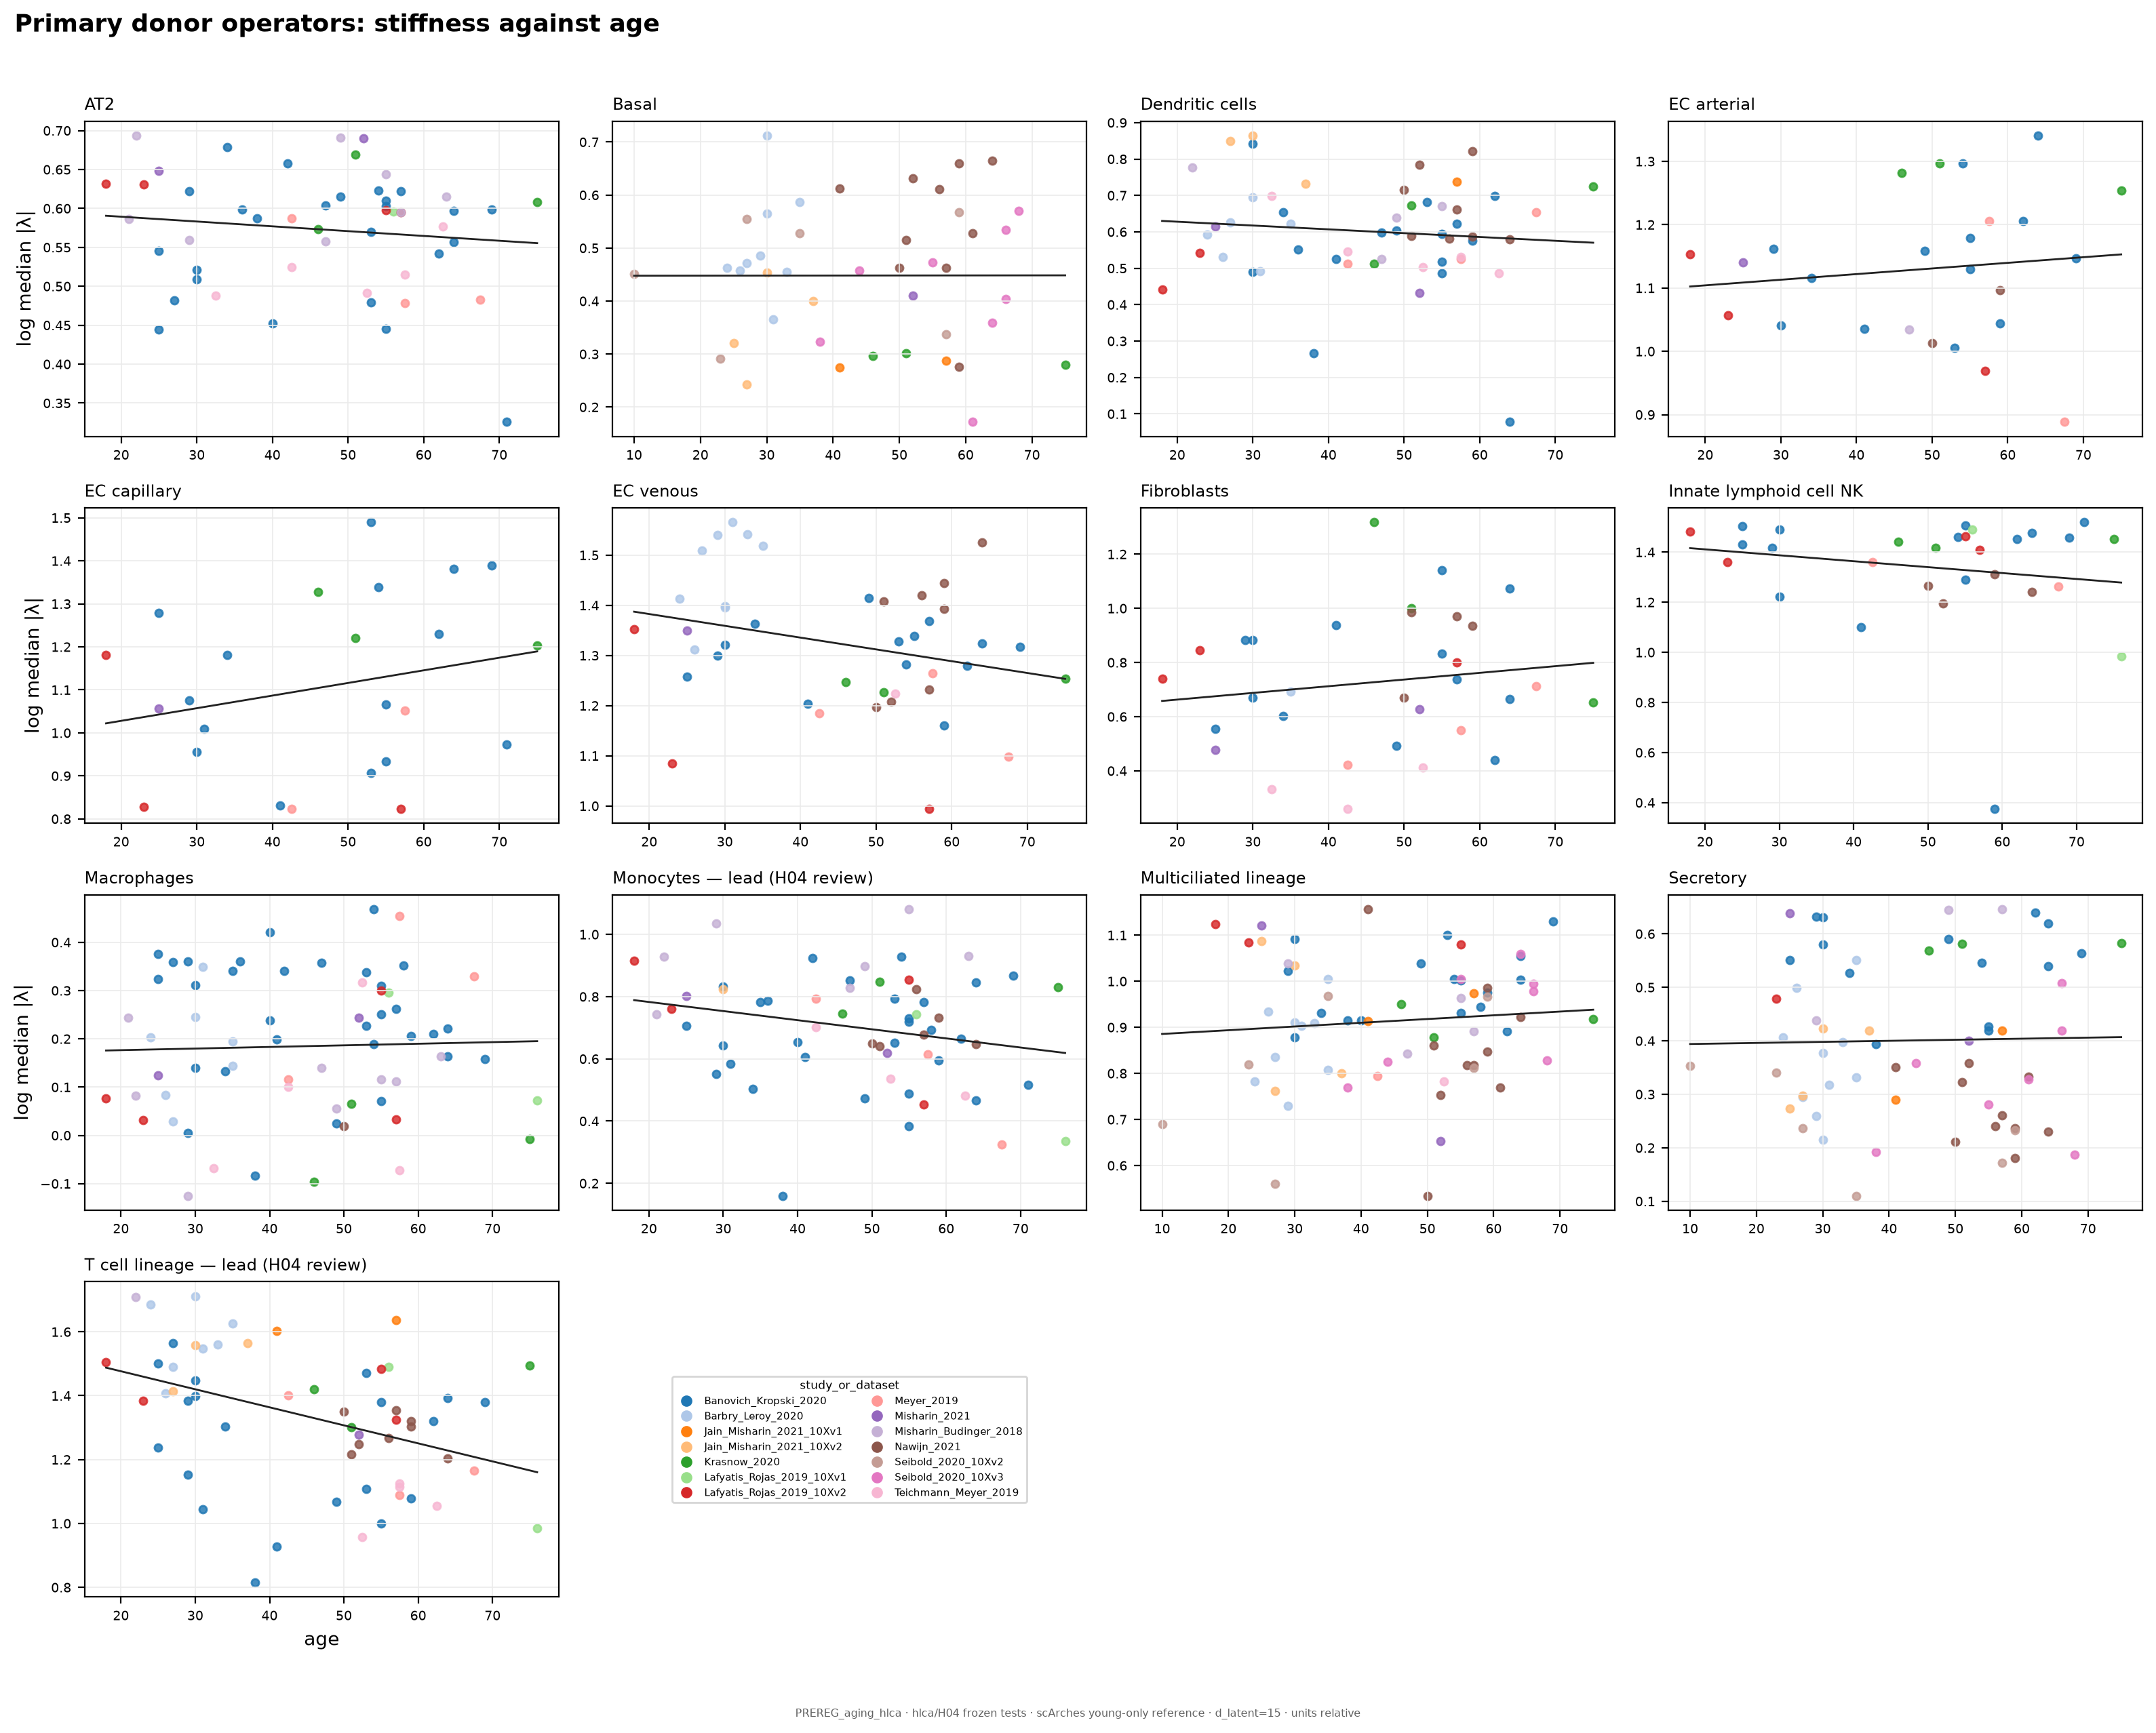

In [5]:
display(Image(filename=str(FIGURE_DIR / 'stiffness_vs_age.png'), width=1000))

## EC-capillary anticipation display

Shows primary stored donor centroids projected onto the young-reference soft axis against age. The source H5AD is accessed only via `HLCA_DATA`, as specified.

{'stored_drift_cells': 56904, 'representation': ['X_drift_v', 'X_scVI_primary']}


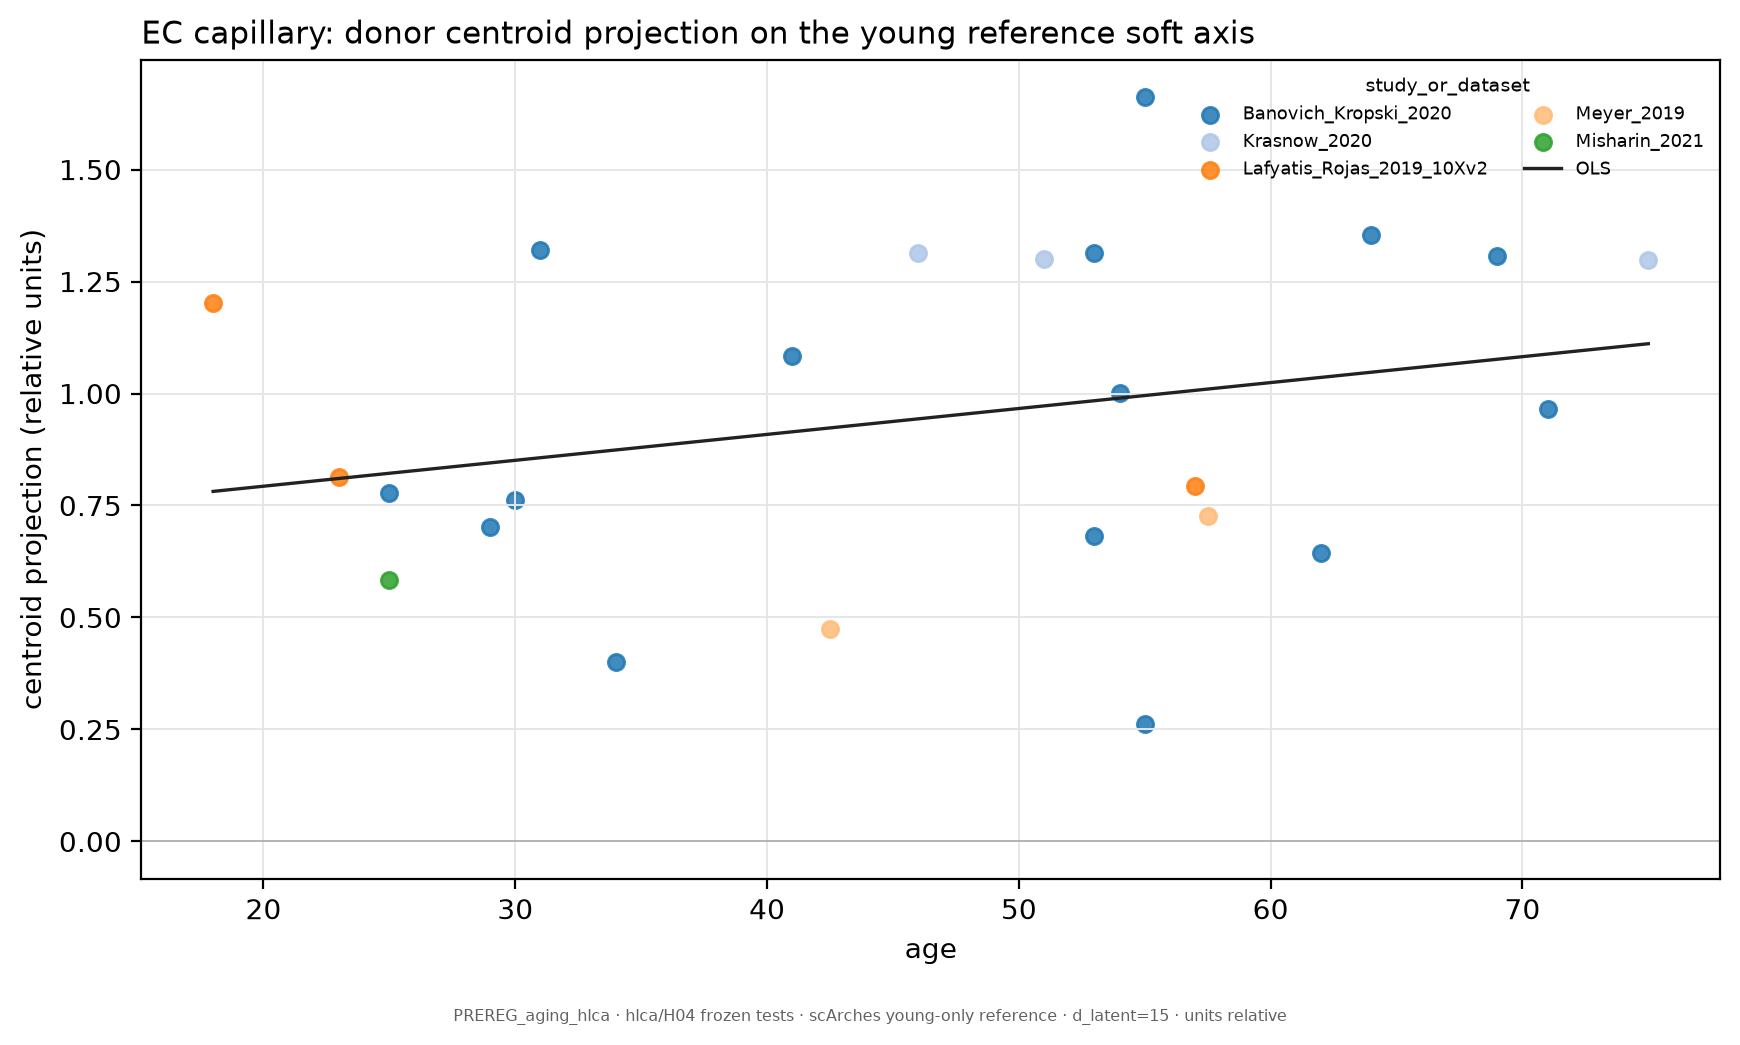

In [6]:
drift = ad.read_h5ad(HLCA_DATA / 'h03_primary_drift.h5ad', backed='r')
try:
    print({'stored_drift_cells': drift.n_obs, 'representation': list(drift.obsm.keys())})
finally:
    drift.file.close()
display(Image(filename=str(FIGURE_DIR / 'ec_capillary_anticipation.png'), width=1000))

## Pre-registered mouse–human comparison

Shows only the two §8 matched pairs. Mouse points are the stored A03 old/young stiffness ratio with the X04 shared-seed range; human points are `exp(stiff_slope)` from H04 §7(f). Calls are text only. This is descriptive; no statistic is computed.

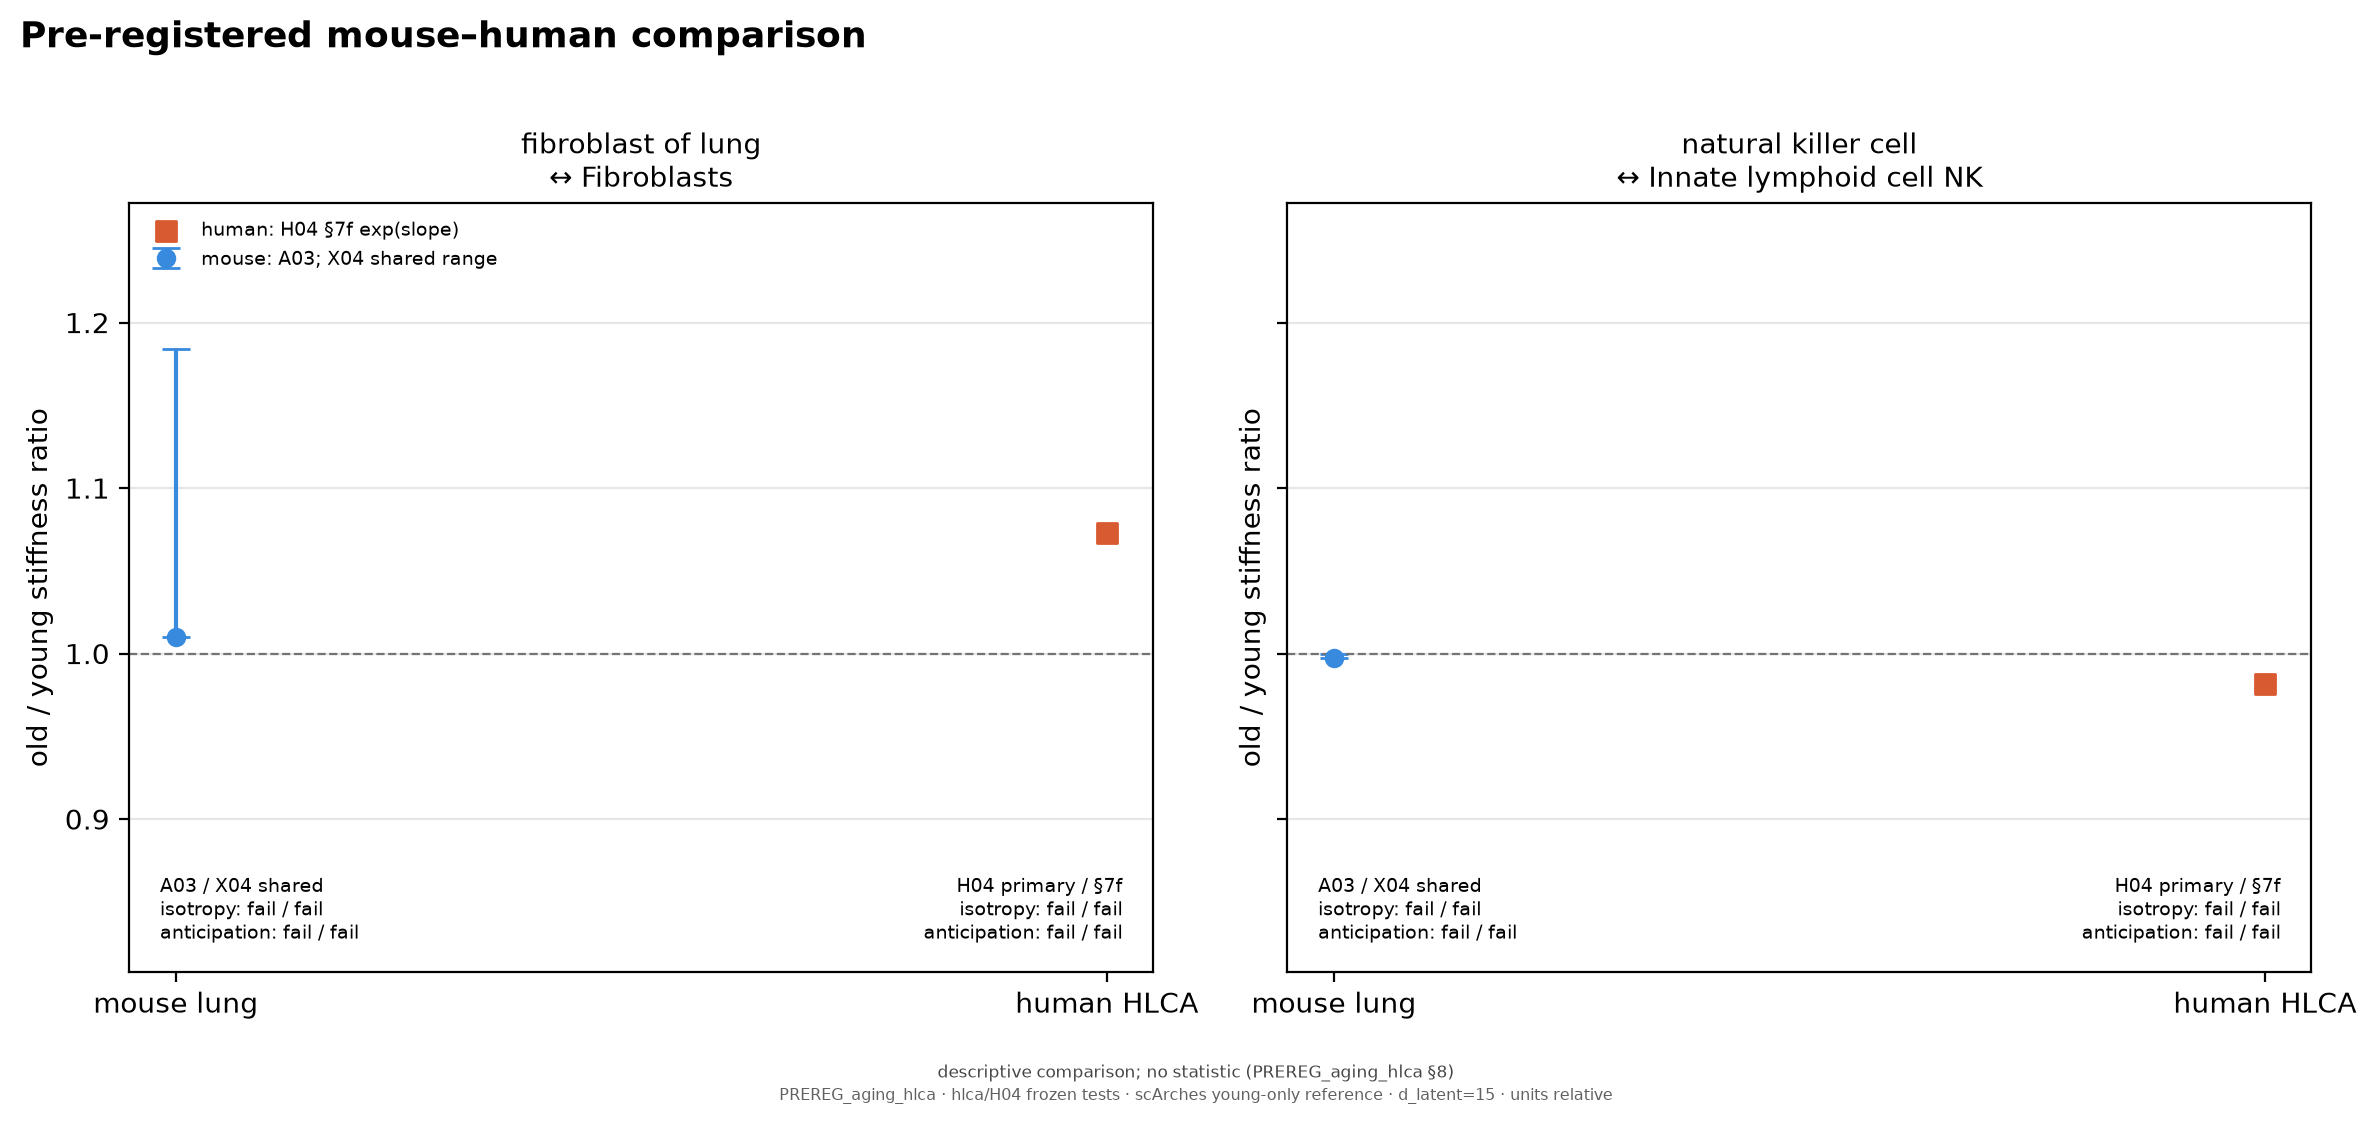

In [7]:
display(Image(filename=str(FIGURE_DIR / 'mouse_human.png'), width=1000))

## QC: scVI history

Shows the stored young-reference and older-query validation ELBO histories from H03.

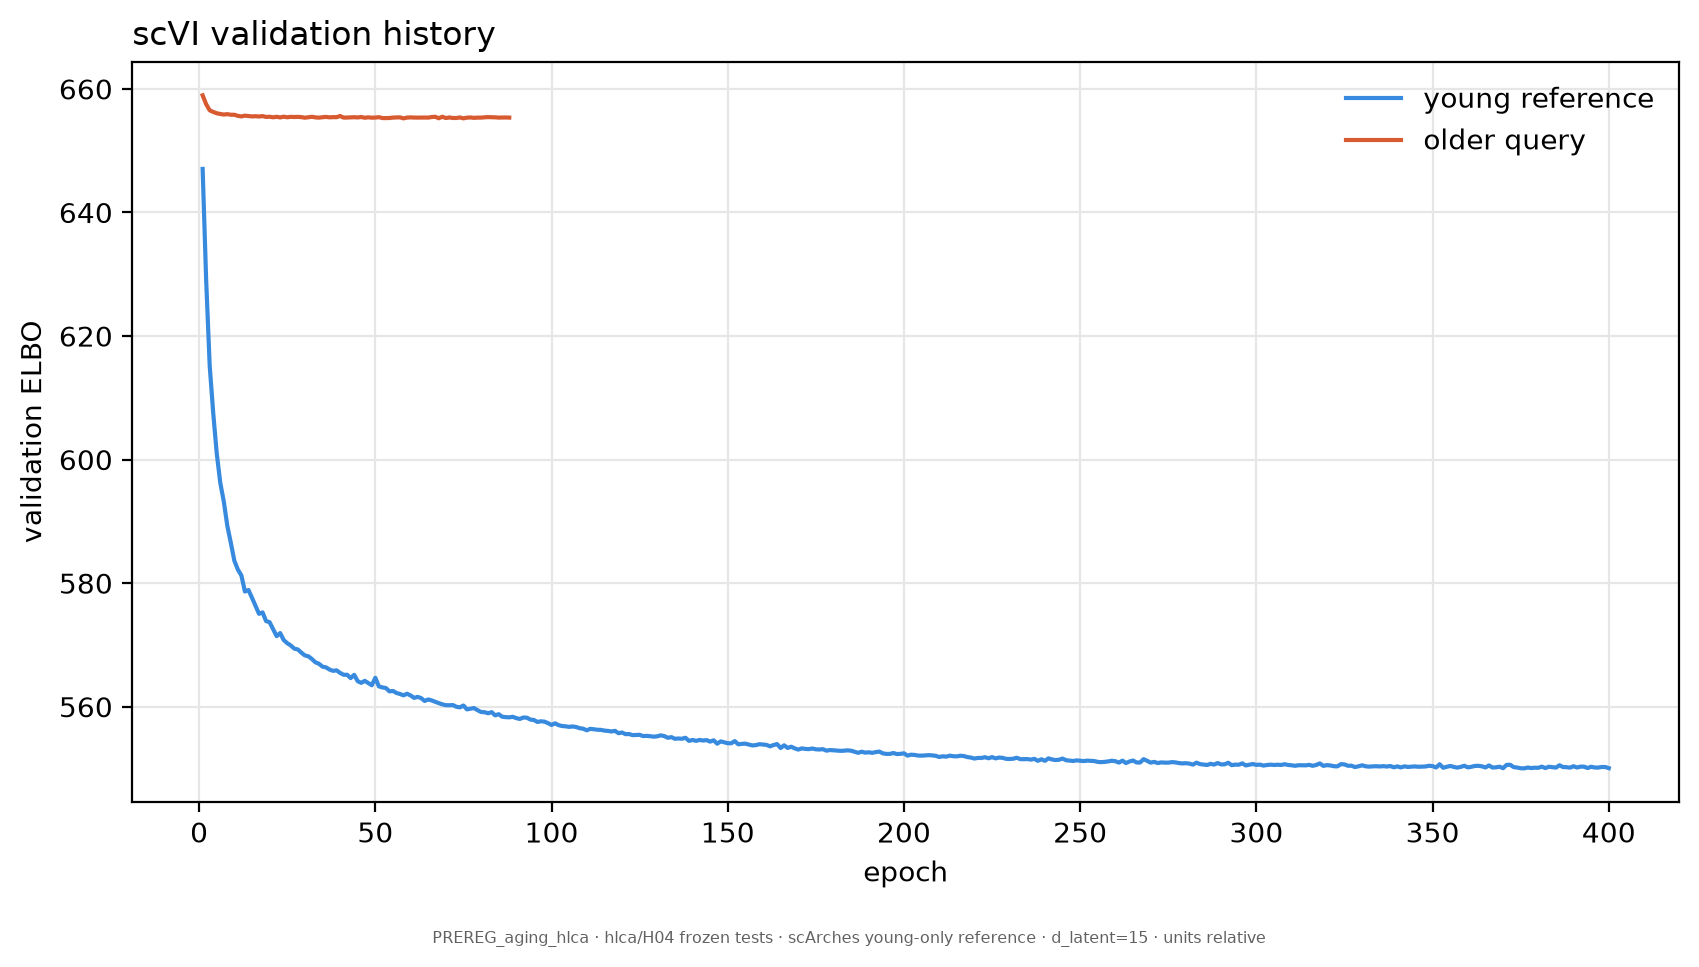

In [8]:
display(Image(filename=str(FIGURE_DIR / 'qc_scvi_history.png'), width=1000))

## QC: final query versus reference ELBO

Shows the two stored best validation ELBO values reported by H03.

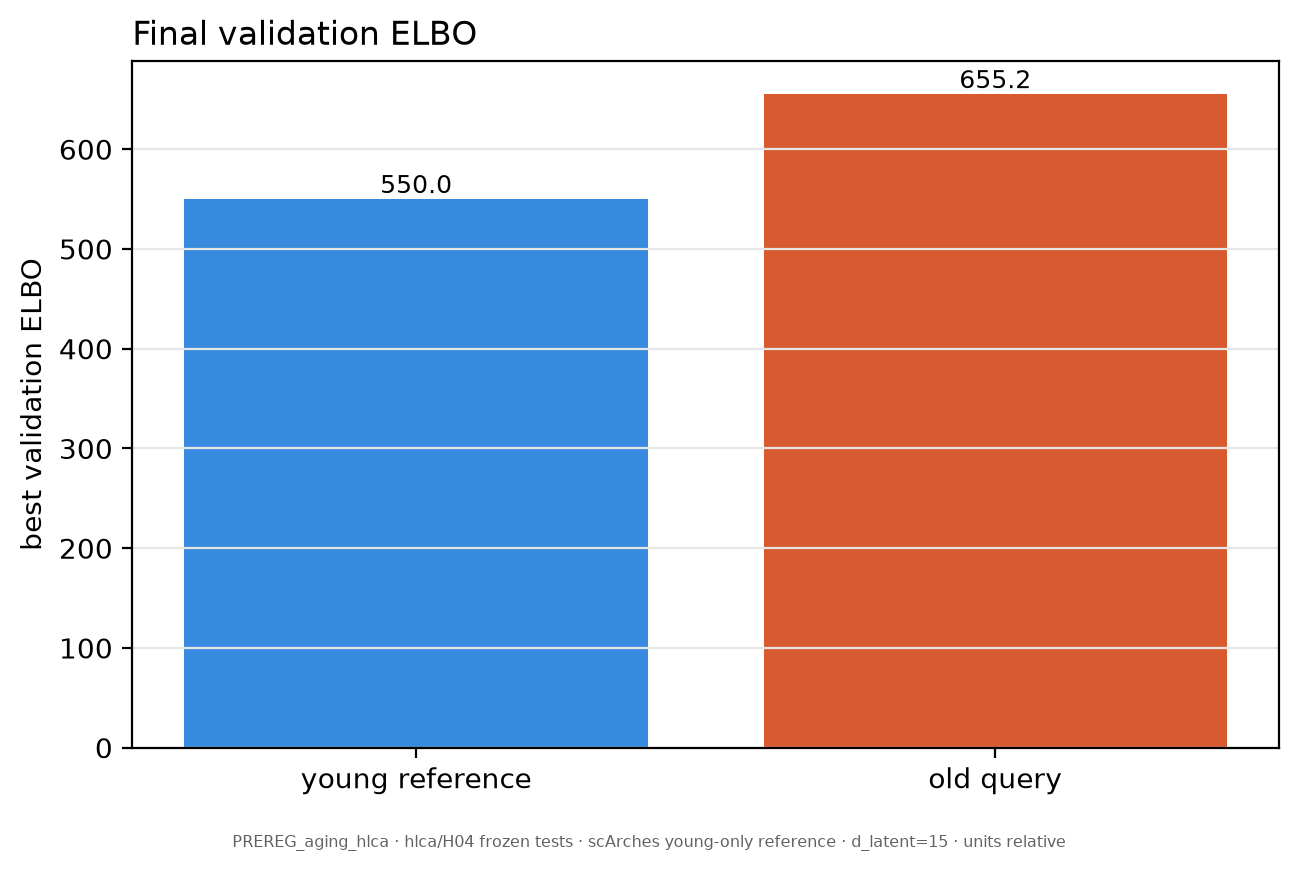

In [9]:
display(Image(filename=str(FIGURE_DIR / 'qc_query_vs_ref_elbo.png'), width=1000))

## QC: energy-drift symmetry

Shows the stored primary and secondary maximum Jacobian asymmetry values against the H03 symmetry gate.

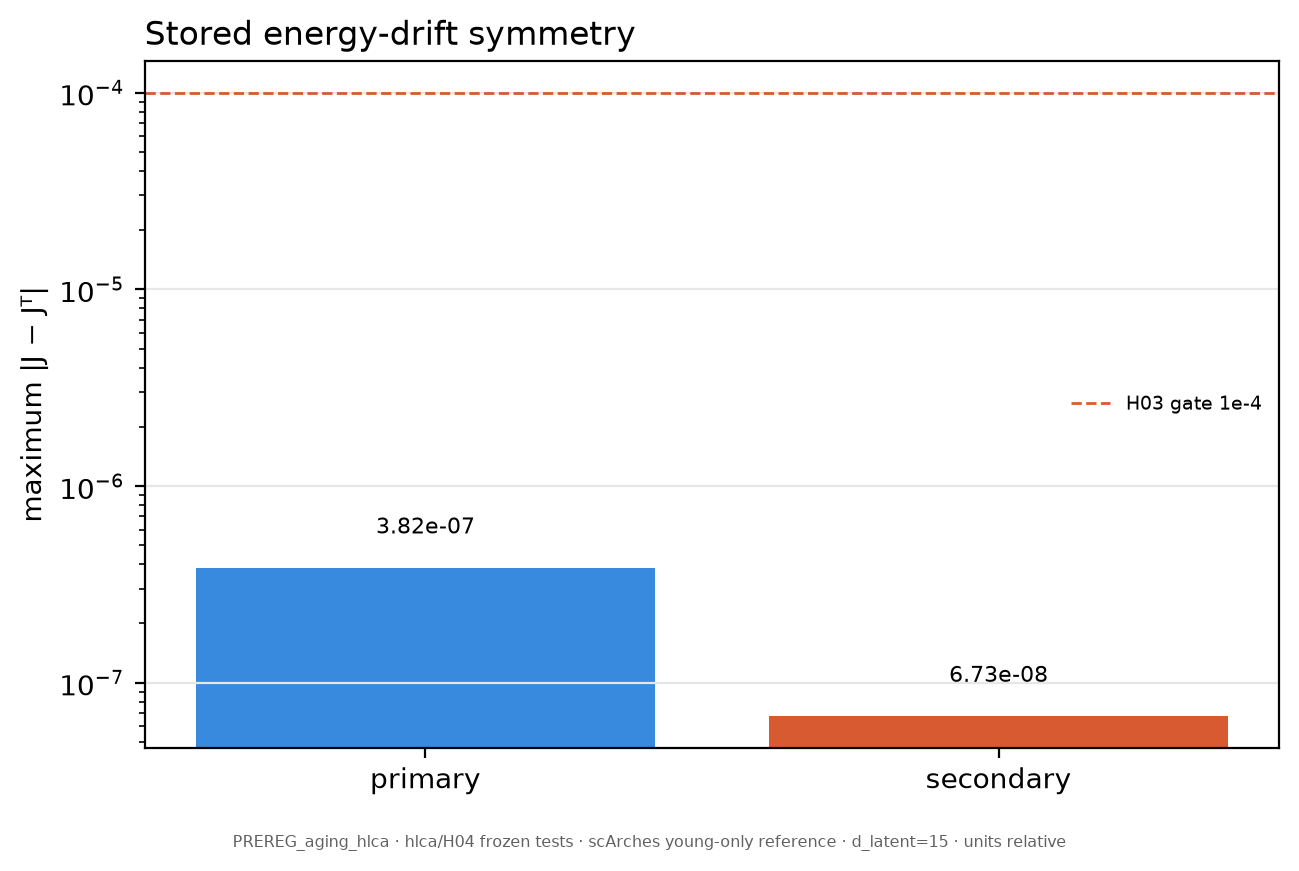

In [10]:
display(Image(filename=str(FIGURE_DIR / 'qc_symmetry.png'), width=1000))

## QC: eligibility counts

Shows the stored H03/H04 count of eligible types for primary, Banovich-only, parenchyma-only, and never-smoker analyses.

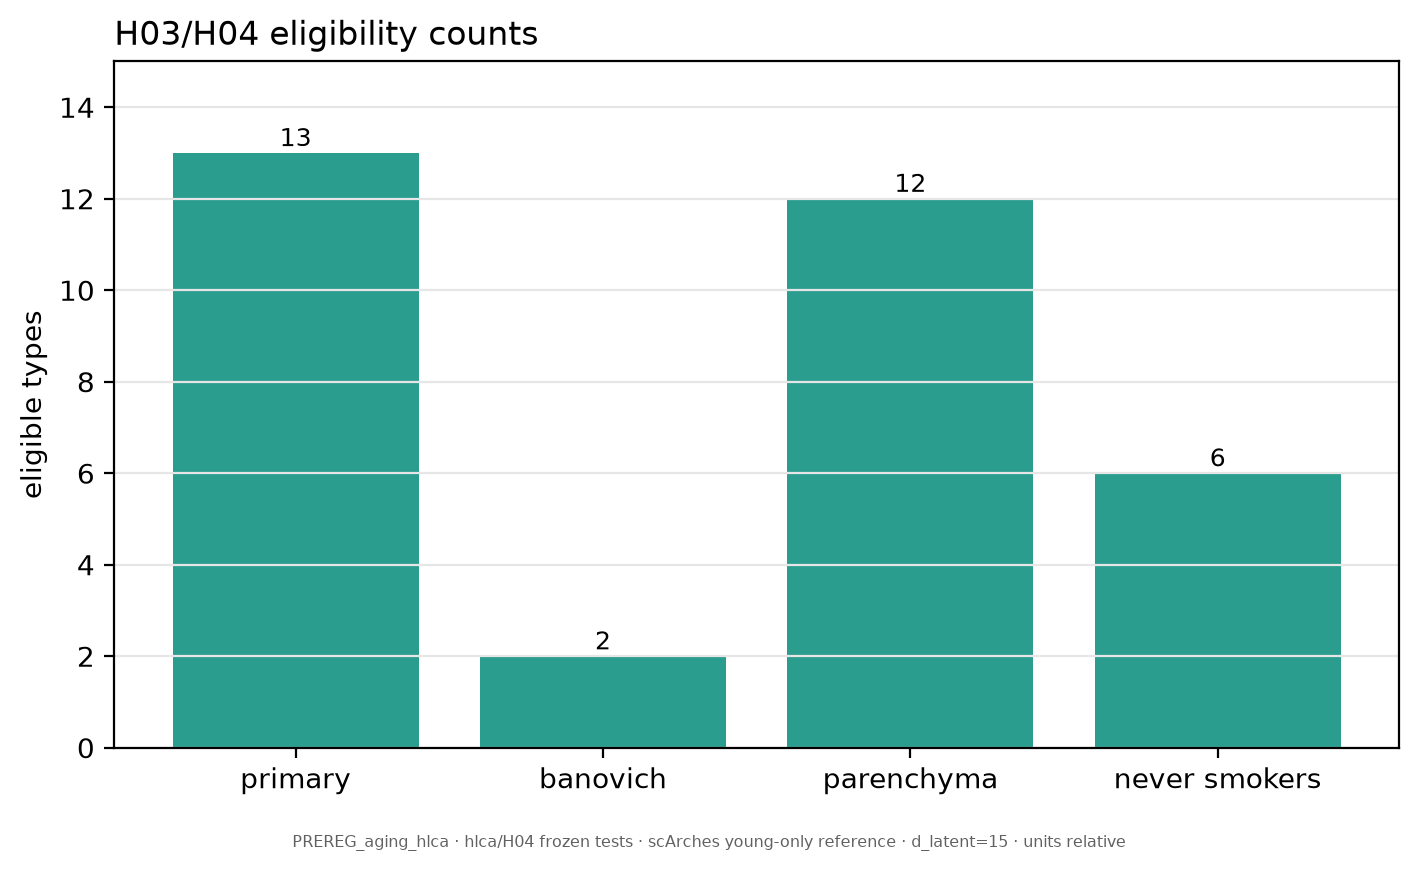

In [11]:
display(Image(filename=str(FIGURE_DIR / 'qc_eligibility_counts.png'), width=1000))

## QC: donor composition

Shows unique donors by age bin and study. The figure is derived from stored H03 drift metadata through the `HLCA_DATA` path variable.

{'unique_donors_in_drift_sample': 106, 'donors_age_ge_60': 17}


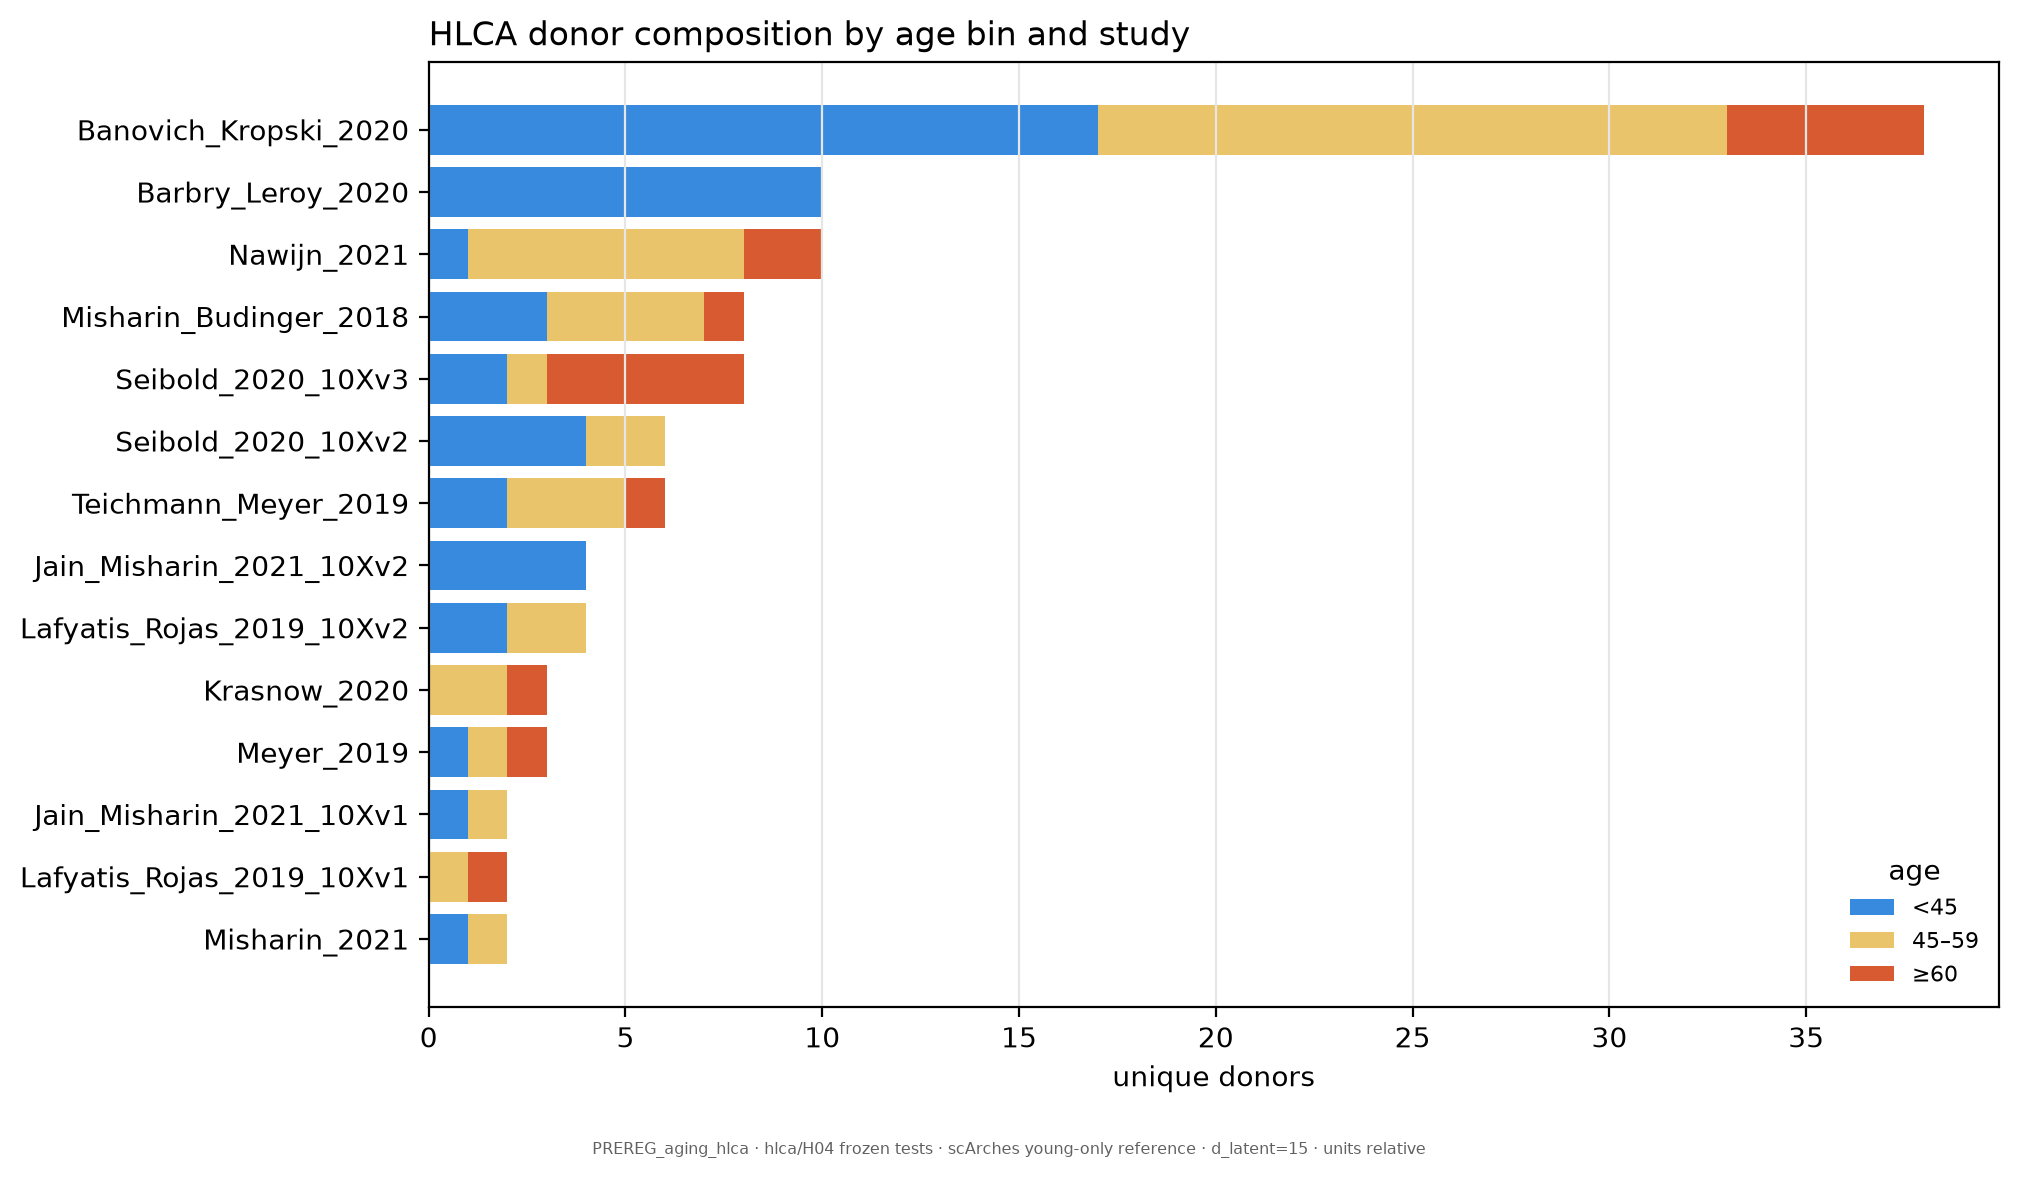

In [12]:
drift = ad.read_h5ad(HLCA_DATA / 'h03_primary_drift.h5ad', backed='r')
try:
    donor_meta = drift.obs[['donor_id', 'age', 'study_or_dataset']].drop_duplicates('donor_id')
finally:
    drift.file.close()
print({'unique_donors_in_drift_sample': len(donor_meta), 'donors_age_ge_60': int((donor_meta['age'] >= 60).sum())})
display(Image(filename=str(FIGURE_DIR / 'qc_donor_composition.png'), width=1000))

## Mouse–human values

The committed two-row descriptive comparison table used by the figure.

In [13]:
display(mouse_human)

,mouse_tissue,mouse_cell_type,human_ann_level_3,mouse_a03_stiffness_ratio,mouse_x04_shared_stiffness_min,mouse_x04_shared_stiffness_max,human_two_group_stiffness_ratio,mouse_a03_iso_pass,mouse_a03_ant_pass,mouse_x04_shared_iso_call,mouse_x04_shared_ant_call,human_primary_iso_pass,human_primary_ant_pass,human_two_group_iso_pass,human_two_group_ant_pass
0,lung,fibroblast of lung,Fibroblasts,1.010274,1.010274,1.184309,1.073117,False,False,fail,fail,False,False,False,False
1,lung,natural killer cell,Innate lymphoid cell NK,0.997260,0.997260,0.999567,0.981729,False,False,fail,fail,False,False,False,False


## Figure manifest

Every PDF and PNG delivered by H05, with the committed source files used for that rendering.

In [14]:
display(manifest)

,path,figure,source_files
0,benchmarks/figures/aging_hlca/tests_overview.pdf,tests_overview,benchmarks/aging_hlca/tests_primary.csv
1,benchmarks/figures/aging_hlca/tests_overview.png,tests_overview,benchmarks/aging_hlca/tests_primary.csv
2,benchmarks/figures/aging_hlca/sensitivity_heat...,sensitivity_heatmap,benchmarks/aging_hlca/tests_primary.csv;benchm...
3,benchmarks/figures/aging_hlca/sensitivity_heat...,sensitivity_heatmap,benchmarks/aging_hlca/tests_primary.csv;benchm...
4,benchmarks/figures/aging_hlca/stiffness_vs_age...,stiffness_vs_age,benchmarks/aging_hlca/donor_operators.csv
5,benchmarks/figures/aging_hlca/stiffness_vs_age...,stiffness_vs_age,benchmarks/aging_hlca/donor_operators.csv
6,benchmarks/figures/aging_hlca/ec_capillary_ant...,ec_capillary_anticipation,benchmarks/aging_hlca/donor_operators.csv;benc...
7,benchmarks/figures/aging_hlca/ec_capillary_ant...,ec_capillary_anticipation,benchmarks/aging_hlca/donor_operators.csv;benc...
8,benchmarks/figures/aging_hlca/mouse_human.pdf,mouse_human,benchmarks/aging/compare_pooled.csv;benchmarks...
9,benchmarks/figures/aging_hlca/mouse_human.png,mouse_human,benchmarks/aging/compare_pooled.csv;benchmarks...
